# Randomized quicksort: sort time vs. array size

This notebook graphs the times measured by the Go program in this folder.

The program sorts arrays of size n = 100, 250, …, 2000 holding the numbers 0 to n-1.
For each size it shuffles the array and times `quickSort` 50 times, then writes every
measurement to `output/times.csv` with the columns `n`, `run` and `nanoseconds`.

To regenerate the data, run the program **from this folder** so the files land in
`quickSort/output/`:

```bash
go run .
```

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Colorblind-safe colors on a near-white surface.
SURFACE = "#fcfcfb"
RUNS_COLOR = "#86b6ef"
AVERAGE_COLOR = "#2a78d6"
INK = "#0b0b0b"
MUTED_INK = "#52514e"
GRID_COLOR = "#e1e0d9"
AXIS_COLOR = "#c3c2b7"
N_LOG_N_COLOR = "#eb6834"
N_SQUARED_COLOR = "#1baf7a"

## Load the measurements

In [15]:
times = pd.read_csv("output/times.csv")
times["microseconds"] = times["nanoseconds"] / 1_000
times.head()

,n,run,nanoseconds,microseconds
0,100,1,4709,4.709
1,100,2,3166,3.166
2,100,3,2958,2.958
3,100,4,3125,3.125
4,100,5,2917,2.917


## Summary per array size

`runs` should be 50 for every size.

In [16]:
summary = (
    times.groupby("n")["microseconds"]
    .agg(runs="count", mean="mean", min="min", max="max", std="std")
    .round(2)
)
summary

,runs,mean,min,max,std
n,,,,,
100,50,2.93,2.67,4.71,0.27
250,50,8.98,7.58,22.83,2.30
500,50,17.27,15.54,30.29,2.55
750,50,25.77,23.83,35.67,2.45
1000,50,34.46,33.17,43.50,1.76
1250,50,46.03,41.62,52.62,3.22
1500,50,56.66,52.25,70.38,3.60
1750,50,65.33,61.42,84.00,4.02
2000,50,75.24,70.21,91.08,3.93


In [17]:
def draw_measurements(ax, times, summary):
    rng = np.random.default_rng(0)
    jitter = rng.uniform(-15, 15, size=len(times))

    ax.scatter(
        times["n"] + jitter,
        times["microseconds"],
        s=14,
        color=RUNS_COLOR,
        alpha=0.7,
        linewidths=0,
        label="Each run (50 per size)",
        zorder=1,
    )
    ax.plot(
        summary.index,
        summary["mean"],
        color=AVERAGE_COLOR,
        linewidth=2,
        marker="o",
        markersize=8,
        markeredgecolor=SURFACE,
        markeredgewidth=2,
        solid_joinstyle="round",
        solid_capstyle="round",
        label="Average",
        zorder=3,
    )


def style_axes(ax, title, last_n):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=13, pad=14)
    ax.set_xlabel("Array size (n)", color=MUTED_INK)
    ax.set_ylabel("Time to sort (µs)", color=MUTED_INK)
    ax.set_xticks(summary.index)
    ax.set_xlim(0, last_n + 250)
    ax.set_ylim(bottom=0)

    ax.grid(axis="y", color=GRID_COLOR, linewidth=1)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS_COLOR)
    ax.tick_params(colors=MUTED_INK, length=0)
    ax.legend(frameon=False, loc="upper left", labelcolor=INK)

## Time vs. array size

Each light dot is one of the 50 runs for that size. They are spread slightly left and right
so overlapping runs stay visible; every dot still belongs to the size on the axis below it.
The dark line connects the average time for each size.

The graph is also saved to `output/time_vs_n.png`.

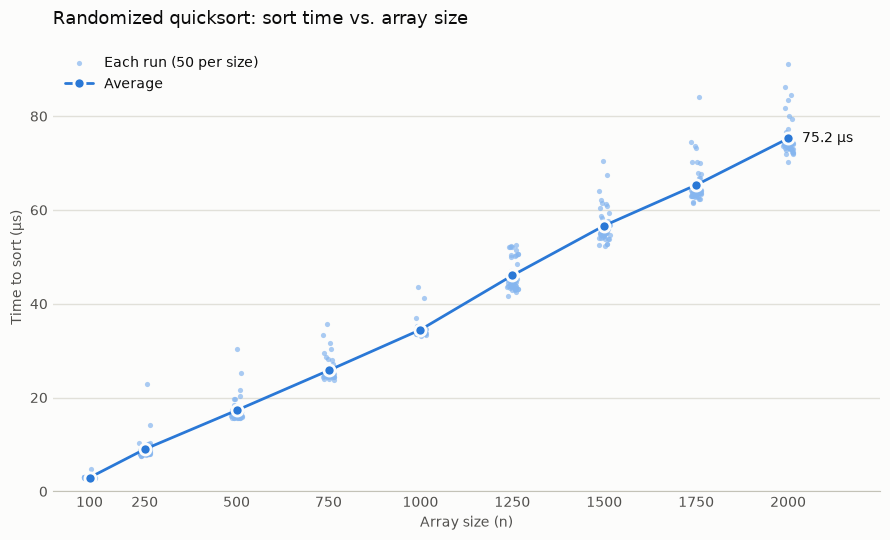

In [18]:
last_n = summary.index[-1]
last_mean = summary["mean"].iloc[-1]

fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=SURFACE)
draw_measurements(ax, times, summary)

ax.annotate(
    f"{last_mean:.1f} µs",
    (last_n, last_mean),
    xytext=(10, 0),
    textcoords="offset points",
    va="center",
    color=INK,
    fontsize=10,
)
style_axes(ax, "Randomized quicksort: sort time vs. array size", last_n)

fig.tight_layout()
fig.savefig("output/time_vs_n.png", dpi=150, facecolor=SURFACE)
plt.show()

## Comparing with $k_1 \cdot n \log_2 n$ and $k_2 \cdot n^2$

Both constants are chosen so the two curves pass through the measured average at $n = 1000$,
which makes all three graphs meet at that point:

$$k_1 = \frac{t(1000)}{1000 \cdot \log_2 1000} \qquad k_2 = \frac{t(1000)}{1000^2}$$

where $t(1000)$ is the average time over the 50 runs with $n = 1000$. The base of the logarithm
only rescales $k_1$; the curve itself, and where it meets the data, stay the same.

The RMSE (root-mean-square error) measures how far each curve is from the averages across all
sizes, in µs. Lower means the curve follows the data better.

In [19]:
ANCHOR_N = 1000


def rmse(predicted, measured):
    return np.sqrt(np.mean((predicted - measured) ** 2))


n = summary.index.to_numpy(dtype=float)
mean_times = times.groupby("n")["microseconds"].mean()
anchor_time = mean_times[ANCHOR_N]
mean_times = mean_times.to_numpy()

n_log_n = n * np.log2(n)
n_squared = n**2

k1 = anchor_time / (ANCHOR_N * np.log2(ANCHOR_N))
k2 = anchor_time / ANCHOR_N**2

print(f"t({ANCHOR_N}) = {anchor_time:.2f} µs")
print(f"k1 = {k1:.4e} µs   RMSE of k1·n·log2(n): {rmse(k1 * n_log_n, mean_times):.2f} µs")
print(f"k2 = {k2:.4e} µs   RMSE of k2·n²:        {rmse(k2 * n_squared, mean_times):.2f} µs")

comparison = pd.DataFrame(
    {
        "measured average (µs)": mean_times,
        "k1·n·log2(n) (µs)": k1 * n_log_n,
        "k2·n² (µs)": k2 * n_squared,
    },
    index=summary.index,
).round(2)
comparison

t(1000) = 34.46 µs
k1 = 3.4580e-03 µs   RMSE of k1·n·log2(n): 1.31 µs
k2 = 3.4462e-05 µs   RMSE of k2·n²:        26.25 µs


,measured average (µs),k1·n·log2(n) (µs),k2·n² (µs)
n,,,
100,2.93,2.30,0.34
250,8.98,6.89,2.15
500,17.27,15.50,8.62
750,25.77,24.77,19.38
1000,34.46,34.46,34.46
1250,46.03,44.47,53.85
1500,56.66,54.73,77.54
1750,65.33,65.19,105.54
2000,75.24,75.84,137.85


## Overlay

The same measurements as above, with both curves on top. All three meet at $n = 1000$.

The graph is also saved to `output/time_vs_n_fits.png`.

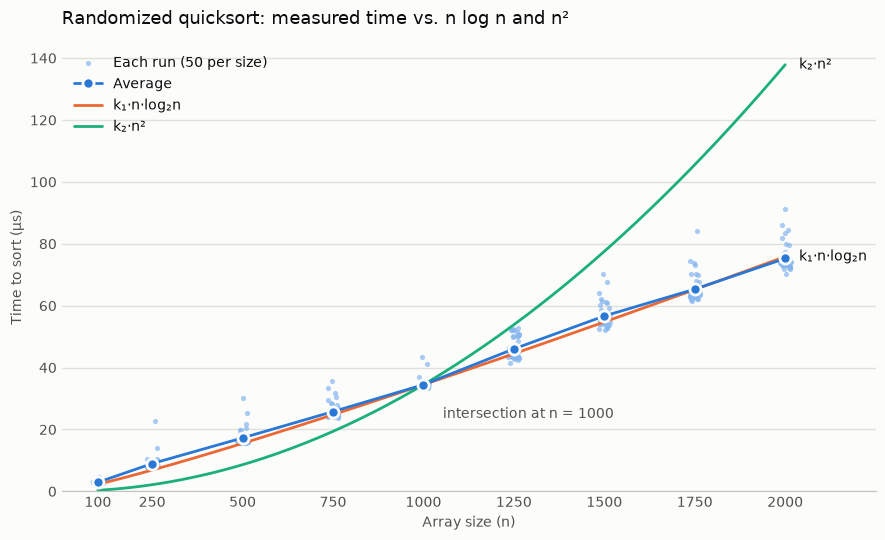

In [20]:
last_n = summary.index[-1]
n_smooth = np.linspace(summary.index[0], last_n, 200)

fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=SURFACE)
draw_measurements(ax, times, summary)

curves = [
    ("k₁·n·log₂n", k1 * n_smooth * np.log2(n_smooth), N_LOG_N_COLOR),
    ("k₂·n²", k2 * n_smooth**2, N_SQUARED_COLOR),
]
for label, values, color in curves:
    ax.plot(
        n_smooth,
        values,
        color=color,
        linewidth=2,
        solid_capstyle="round",
        label=label,
        zorder=2,
    )
    ax.annotate(
        label,
        (n_smooth[-1], values[-1]),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        color=INK,
        fontsize=10,
    )

ax.annotate(
    f"intersection at n = {ANCHOR_N}",
    (ANCHOR_N, anchor_time),
    xytext=(14, -16),
    textcoords="offset points",
    va="top",
    color=MUTED_INK,
    fontsize=10,
)

style_axes(ax, "Randomized quicksort: measured time vs. n log n and n²", last_n)

fig.tight_layout()
fig.savefig("output/time_vs_n_fits.png", dpi=150, facecolor=SURFACE)
plt.show()